# 03 — Validate the silver RPG table and size the apiary registry (S3)

The full ingest has run. Two goals:

1. **Validate** the silver table against the run manifest and the notebook 02 estimate.
2. **Size S3**: how many orchard parcels are realistic apiary sites, and where are they?
   The answers set the business assumptions of the synthetic apiary registry.

Reads only local files (`data/lake/`); no API calls.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

DEPT_CODE = "82"
RPG_YEAR = 2024
CRS_L93 = "EPSG:2154"
ORCHARD_GROUP = "20"
SIZE_THRESHOLDS_HA = [0.5, 1, 2, 5]
NB02_ESTIMATE = (128_772, 200_704)  # returned rows, range from 5 random tiles (notebook 02)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LAKE = ROOT / "data" / "lake"
PARCELS_PATH = LAKE / "silver" / "rpg_parcels" / f"rpg_year={RPG_YEAR}" / f"dept_code={DEPT_CODE}" / "parcels.parquet"
COMMUNES_PATH = LAKE / "silver" / "communes" / f"dept_code={DEPT_CODE}" / "communes.parquet"
MANIFEST_DIR = LAKE / "manifests" / "geo"

pd.set_option("display.width", 160)

## 1 — Run manifest: the row-count funnel

In [2]:
manifest_path = sorted(MANIFEST_DIR.glob("*.json"))[-1]   # file names start with a UTC timestamp
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
s = manifest["stats"]
print("manifest:", manifest_path.name, "| run_id:", manifest["run_id"])
print(f"tiles: {s['tiles_total']} (fetched now {s['tiles_fetched_now']}, from cache {s['tiles_from_cache']})")

after_dedupe = s["rows_raw"] - s["duplicates_removed"]
after_geom = after_dedupe - s["empty_dropped"]
funnel = pd.DataFrame(
    [
        ("returned by API", s["rows_raw"]),
        ("after dedupe", after_dedupe),
        ("after geometry repair", after_geom),
        ("in department (final)", s["rows_final"]),
    ],
    columns=["step", "rows"],
)
funnel["share_of_raw"] = (funnel["rows"] / s["rows_raw"]).map("{:.1%}".format)
display(funnel)

print(f"invalid geometries fixed: {s['invalid_fixed']}, collections split: {s['collections_split']}")
print(f"parcels crossing the boundary (kept): {s['crossing_boundary']}")
lo, hi = NB02_ESTIMATE
print(f"\nnotebook 02 estimate for returned rows: {lo:,} - {hi:,} -> actual {s['rows_raw']:,}",
      "(inside range)" if lo <= s["rows_raw"] <= hi else "(OUTSIDE range: investigate)")

manifest: 20261023T031622Z_a0fd6756.json | run_id: a0fd6756
tiles: 196 (fetched now 0, from cache 196)


,step,rows,share_of_raw
0,returned by API,140211,100.0%
1,after dedupe,130811,93.3%
2,after geometry repair,130811,93.3%
3,in department (final),99057,70.6%


invalid geometries fixed: 1484, collections split: 843
parcels crossing the boundary (kept): 849

notebook 02 estimate for returned rows: 128,772 - 200,704 -> actual 140,211 (inside range)


## 2 — Silver table checks (independent of the pipeline's own validation)

In [3]:
parcels = gpd.read_parquet(PARCELS_PATH)
communes = gpd.read_parquet(COMMUNES_PATH)

checks = {
    "rows match manifest": len(parcels) == s["rows_final"],
    "id_parcel unique": parcels["id_parcel"].is_unique,
    "CRS is EPSG:4326": parcels.crs.to_string() == "EPSG:4326",
    "only MultiPolygon": set(parcels.geom_type) == {"MultiPolygon"},
    "all valid": bool(parcels.is_valid.all()),
    "single run_id": parcels["run_id"].nunique() == 1,
}
display(pd.Series(checks, name="pass"))
print("\nnull share per column:")
print(parcels.drop(columns="geometry").isna().mean().round(3).to_string())

rows match manifest    True
id_parcel unique       True
CRS is EPSG:4326       True
only MultiPolygon      True
all valid              True
single run_id          True
Name: pass, dtype: bool


null share per column:
id_parcel                0.000
surf_parc                0.000
code_cultu               0.000
code_group               0.000
culture_d1               0.999
culture_d2               0.999
cat_cult_p               0.093
source_tile_id           0.000
crosses_dept_boundary    0.000
dept_code                0.000
rpg_year                 0.000
source                   0.000
run_id                   0.000
ingested_at_utc          0.000


## 3 — Crop codes at department scale

Deferred from notebook 02: the full table finally lets us check, on every parcel,
that each `code_cultu` maps to exactly one `code_group`. `dim_crop` relies on it.

In [4]:
pairs = parcels.groupby("code_cultu")["code_group"].nunique()
violations = pairs[pairs > 1]
print("code_cultu values:", len(pairs), "| mapped to more than one group:", len(violations))
if len(violations):
    display(parcels[parcels["code_cultu"].isin(violations.index)]
            .groupby(["code_cultu", "code_group"]).size().rename("parcels"))

code_cultu values: 123 | mapped to more than one group: 0


In [5]:
by_group = (parcels.assign(area_ha=parcels["surf_parc"])
            .groupby("code_group")
            .agg(parcels=("id_parcel", "size"), area_ha=("area_ha", "sum"))
            .sort_values("area_ha", ascending=False))
by_group["area_share"] = (by_group["area_ha"] / by_group["area_ha"].sum()).map("{:.1%}".format)
display(by_group.head(15))

,parcels,area_ha,area_share
code_group,,,
18,18188,36497.01,17.5%
1,6281,25646.11,12.3%
6,6183,24471.11,11.8%
2,5101,22149.04,10.6%
16,6004,16269.47,7.8%
4,4334,14328.53,6.9%
11,14262,12914.56,6.2%
20,7068,10278.81,4.9%
19,5086,9601.25,4.6%


In [6]:
orchards = parcels[parcels["code_group"] == ORCHARD_GROUP].copy()
by_code = (orchards.groupby("code_cultu")
           .agg(parcels=("id_parcel", "size"), area_ha=("surf_parc", "sum"),
                median_ha=("surf_parc", "median"))
           .sort_values("area_ha", ascending=False))
by_code["area_share"] = (by_code["area_ha"] / by_code["area_ha"].sum()).map("{:.1%}".format)
print(f"group {ORCHARD_GROUP}: {len(orchards):,} parcels, {orchards['surf_parc'].sum():,.0f} ha")
display(by_code)

group 20: 7,068 parcels, 10,279 ha


,parcels,area_ha,median_ha,area_share
code_cultu,,,,
VRG,3969,7385.25,1.030,71.8%
PRU,1977,2182.05,0.670,21.2%
CBT,635,302.48,0.310,2.9%
PVT,304,235.57,0.445,2.3%
PWT,168,169.29,0.475,1.6%
AGR,3,2.48,0.620,0.0%
PFR,12,1.69,0.105,0.0%


## 4 — Sizing S3: candidate apiary sites

A pollination contract covers an orchard *block*, not a sliver. We count group-20 parcels
above several size thresholds, then look at where they concentrate.

In [7]:
rows = []
for t in SIZE_THRESHOLDS_HA:
    cand = orchards[orchards["surf_parc"] >= t]
    rows.append({"min_ha": t, "parcels": len(cand), "area_ha": round(cand["surf_parc"].sum()),
                 "share_of_orchard_area": cand["surf_parc"].sum() / orchards["surf_parc"].sum()})
sizing = pd.DataFrame(rows)
sizing["share_of_orchard_area"] = sizing["share_of_orchard_area"].map("{:.0%}".format)
display(sizing)

,min_ha,parcels,area_ha,share_of_orchard_area
0,0.5,4596,9658,94%
1,1.0,2935,8452,82%
2,2.0,1421,6347,62%
3,5.0,350,3081,30%


In [8]:
# Where are the orchards? Assign each parcel to a commune by its representative point.
orch_l93 = orchards.to_crs(CRS_L93)
points = gpd.GeoDataFrame(orch_l93[["id_parcel", "surf_parc"]],
                          geometry=orch_l93.representative_point(), crs=CRS_L93)
joined = gpd.sjoin(points, communes.to_crs(CRS_L93)[["commune_name", "geometry"]],
                   how="left", predicate="within")
by_commune = (joined.groupby("commune_name")["surf_parc"].agg(["size", "sum"])
              .rename(columns={"size": "parcels", "sum": "orchard_ha"})
              .sort_values("orchard_ha", ascending=False))
by_commune["cum_share"] = (by_commune["orchard_ha"].cumsum() / by_commune["orchard_ha"].sum())
print(f"communes with orchards: {len(by_commune)} / {len(communes)}")
print("communes holding 50% of orchard area:", int((by_commune["cum_share"] < 0.5).sum()) + 1)
display(by_commune.head(15).round({"orchard_ha": 0, "cum_share": 2}))

communes with orchards: 141 / 195
communes holding 50% of orchard area: 12


,parcels,orchard_ha,cum_share
commune_name,,,
Moissac,821,985.0,0.10
Montauban,481,919.0,0.19
Castelsarrasin,240,763.0,0.26
Bressols,77,343.0,0.29
Lizac,290,317.0,0.32
Cazes-Mondenard,336,310.0,0.35
Albias,132,305.0,0.38
Lafrançaise,282,285.0,0.41
Montech,86,278.0,0.44


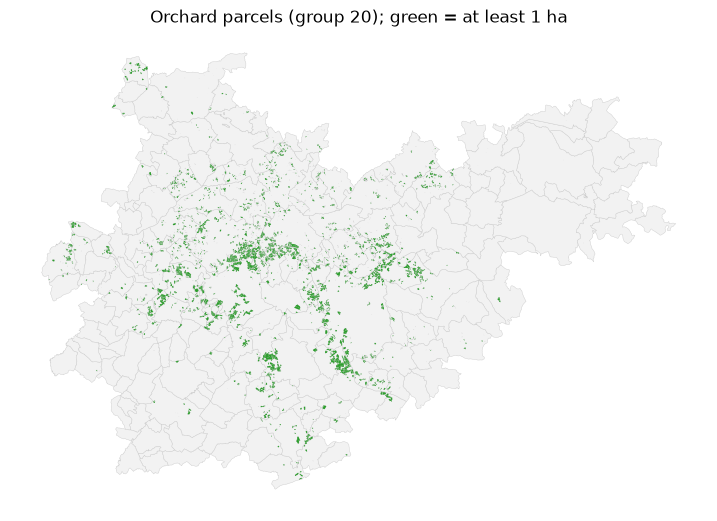

In [9]:
fig, ax = plt.subplots(figsize=(9, 8))
communes.to_crs(CRS_L93).plot(ax=ax, color="#f2f2f2", edgecolor="#cccccc", linewidth=0.3)
orch_l93.plot(ax=ax, color="#bbbbbb", linewidth=0)
orch_l93[orch_l93["surf_parc"] >= 1].plot(ax=ax, color="tab:green", linewidth=0)
ax.set_title(f"Orchard parcels (group {ORCHARD_GROUP}); green = at least 1 ha")
ax.set_axis_off()
plt.show()

## Findings

- **Funnel:** returned 140,211 → after dedupe 130,811 (−9,400 cross-tile copies, 1 split record merged)
  → after geometry repair 130,811 (1,484 repaired, 843 collections split, 0 dropped)
  → final 99,057 (−31,754 outside the department; 849 boundary-crossing parcels kept and flagged).
  Returned rows fall **inside** the notebook 02 range (128,772–200,704), 5% below its mean.
- **Silver checks:** all 6 pass, checked outside the pipeline: row count matches the manifest,
  unique `id_parcel`, EPSG:4326, MultiPolygon only, all valid, single `run_id`.
  `culture_d1` / `culture_d2` 99.9% null (kept on purpose), `cat_cult_p` 9.3% null.
- **Code → group mapping:** 123 `code_cultu` values, **0 violations**. Every code maps to exactly
  one `code_group`, so `dim_crop` can derive the group from the parcels.
- **Orchards (group 20):** 7,068 parcels, 10,279 ha (4.9% of the department's declared area).
  - **VRG holds 71.8% of orchard area** (7,385 ha). Apple and kiwi have no PAC code, so they are hidden there.
  - Plum (PRU) is the second orchard crop: 21.2%, 2,182 ha. Cherry 2.9%, peach 2.3%, pear 1.6%.
  - PFR (berries) totals only 1.7 ha, so kiwi (several hundred ha in the department) cannot be
    declared under PFR: kiwi must sit in VRG.
- **S3 sizing:** parcels ≥ 1 ha = **2,935** (8,452 ha, 82% of orchard area).
  - The threshold curve: ≥ 0.5 ha keeps 94% of area with 4,596 parcels; ≥ 2 ha keeps 62% with 1,421;
    ≥ 5 ha keeps 30% with 350.
  - Orchards are spread over 141 / 195 communes, but **12 communes hold 50% of orchard area**
    (Moissac, Montauban and Castelsarrasin alone: 26%). Apiaries should cluster along the
    Moissac – Castelsarrasin – Montauban axis, with a secondary area around Lafrançaise / Lizac /
    L'Honor-de-Cos.